In [1]:
import numpy as np
import matplotlib.pyplot as plt

from tqdm.auto import tqdm

from beta_evidence_field import (OccupancyField, OccupancyObservation, OccupancyPrior)
from tools.plotting      import configure_plots, plot_evidence_2d, plot_query_2d

configure_plots()

In [2]:
SPATIAL_DIMENSIONS = (-1.5, -1.5, 4.0, 4.0)
SPATIAL_RESOLUTION = 100

ANGLE_OFFSET       = np.deg2rad(45)
ANGLE_RANGE        = (np.deg2rad(-30), np.deg2rad(30))
ANGLE_RESOLUTION   = 10

OBSERVATION_RANGE  = 3.0

In [3]:
field        = OccupancyField.from_yaml("../config/example_2d_config.yaml")
observations = []

observation = OccupancyObservation(origin    = np.array([0.0, 0.0]),
                                   direction = np.array([np.cos(ANGLE_OFFSET), np.sin(ANGLE_OFFSET)]),
                                   range     = OBSERVATION_RANGE,
                                   returned  = True,
                                   time      = 0.0)

for angle in tqdm(np.linspace(ANGLE_RANGE[0], ANGLE_RANGE[1], ANGLE_RESOLUTION), desc = "Generating observations"):
    observations.append(OccupancyObservation(origin    = np.array([0.0, 0.0]),
                                             direction = np.array([np.cos(angle + ANGLE_OFFSET), np.sin(angle + ANGLE_OFFSET)]),
                                             range     = OBSERVATION_RANGE,
                                             returned  = True,
                                             time      = 0.0))

field.clear()
obs = field.add(observations)

Generating observations:   0%|          | 0/10 [00:00<?, ?it/s]

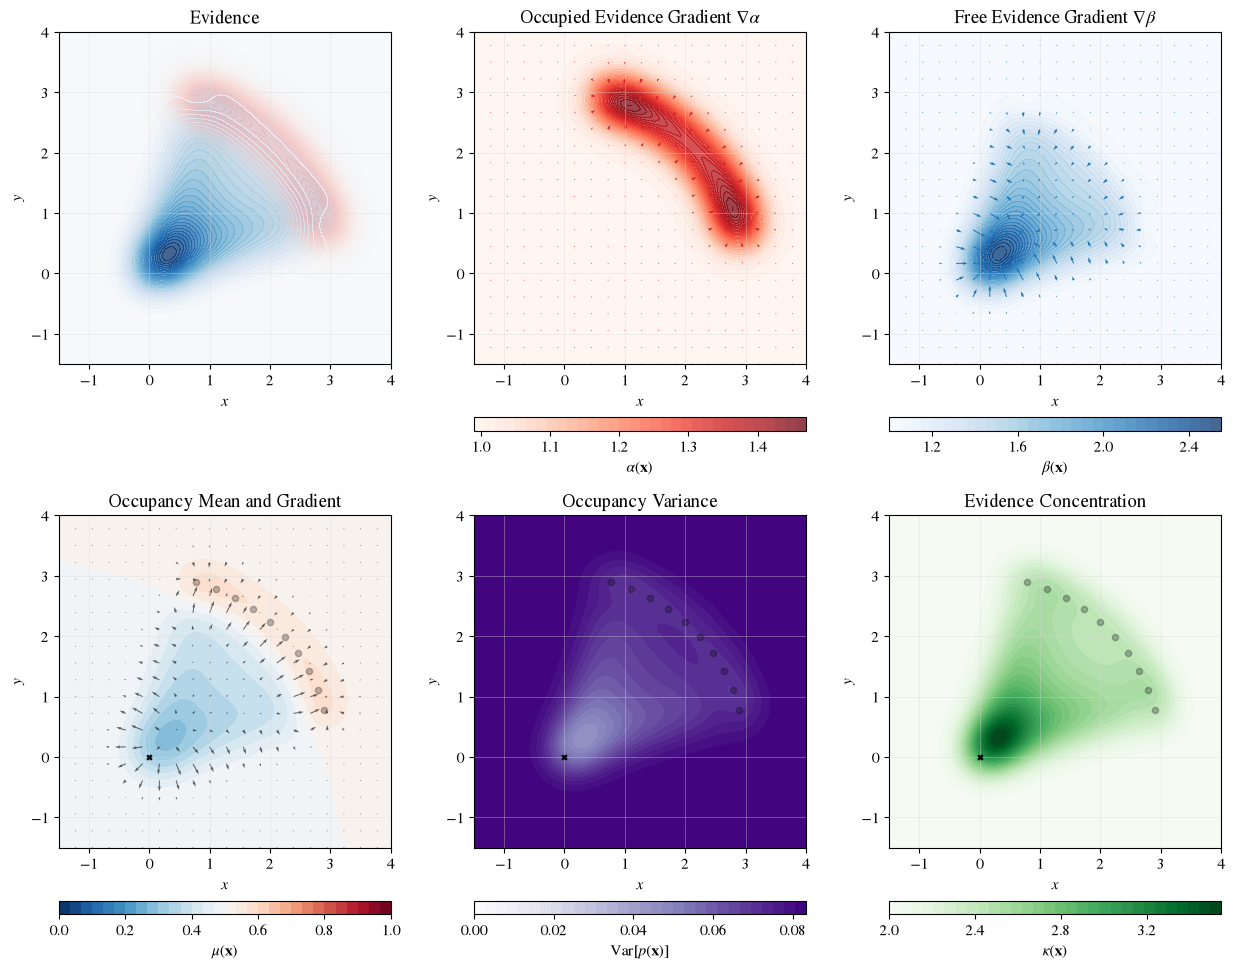

In [4]:
x = np.linspace(SPATIAL_DIMENSIONS[0], SPATIAL_DIMENSIONS[2], SPATIAL_RESOLUTION)
y = np.linspace(SPATIAL_DIMENSIONS[1], SPATIAL_DIMENSIONS[3], SPATIAL_RESOLUTION)

X, Y = np.meshgrid(x, y, indexing = "ij")

fig, axes = plt.subplots(2, 3, figsize = (15, 11))
fig.subplots_adjust(hspace = 0.33, wspace = 0.25)

plot_evidence_2d(X     = X,
                 Y     = Y,
                 field = field,
                 axes  = axes[0])

plot_query_2d(X     = X,
              Y     = Y,
              field = field,
              axes  = axes[1])